In [ ]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn gradio

In [ ]:
print("installation complete")

installation complete


In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


NLTK resources downloaded successfully!


[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [ ]:
taxonomy = {
    "Heart Conditions": [
        "coronary_artery_disease",
        "arrhythmia"
    ],

    "Symptoms & Diagnosis": [
        "heart_symptoms",
        "diagnostic_tests"
    ],

    "Prevention & Lifestyle": [
        "heart_diet",
        "exercise_lifestyle"
    ],

    "Medication & Treatment": [
        "heart_medication",
        "heart_treatment"
    ],

    "Complications & Emergencies": [
        "heart_failure",
        "heart_emergency"
    ]
}

In [ ]:
data = {

    "coronary_artery_disease": [
        "What is coronary artery disease?",
        "Explain the causes of blocked heart arteries.",
        "How does plaque build up in arteries?",
        "What happens when coronary arteries become narrow?",
        "What are the risk factors for coronary artery disease?",
        "Can high cholesterol cause artery blockage?"
    ],

    "arrhythmia": [
        "What is cardiac arrhythmia?",
        "Why does my heart beat irregularly?",
        "What causes an abnormal heart rhythm?",
        "Explain atrial fibrillation.",
        "Why do I sometimes feel skipped heartbeats?",
        "What are the different types of arrhythmia?"
    ],

    "heart_symptoms": [
        "What are the common symptoms of heart disease?",
        "Why do I experience chest discomfort?",
        "Can heart problems cause dizziness?",
        "What are the warning signs of poor heart health?",
        "Why do I feel breathless sometimes?",
        "Can unusual fatigue indicate a heart problem?"
    ],

    "diagnostic_tests": [
        "What is an ECG test?",
        "How does an echocardiogram work?",
        "Why do doctors recommend a stress test?",
        "What is a cardiac MRI?",
        "How is blood pressure measured?",
        "What does a cholesterol test indicate?"
    ],

    "heart_diet": [
        "What foods are good for heart health?",
        "Which foods should heart patients avoid?",
        "Is eating too much salt harmful to the heart?",
        "How does a healthy diet prevent heart disease?",
        "Are nuts beneficial for the heart?",
        "What is a heart healthy diet?"
    ],

    "exercise_lifestyle": [
        "How does exercise improve heart health?",
        "How much physical activity is good for the heart?",
        "Does walking reduce heart disease risk?",
        "Can smoking damage the heart?",
        "How does sleep affect cardiovascular health?",
        "Can stress increase the risk of heart disease?"
    ],

    "heart_medication": [
        "What are beta blockers used for?",
        "Why are statins prescribed?",
        "What do blood thinners do?",
        "How do blood pressure medicines work?",
        "What are common medications for heart conditions?",
        "Why do doctors prescribe cholesterol medicines?"
    ],

    "heart_treatment": [
        "What is angioplasty?",
        "How does a pacemaker work?",
        "What is coronary bypass surgery?",
        "When is a stent required?",
        "What treatments are available for blocked arteries?",
        "What is cardiac rehabilitation?"
    ],

    "heart_failure": [
        "What is congestive heart failure?",
        "Why does heart failure cause swelling?",
        "What are the symptoms of heart failure?",
        "Can heart failure cause breathing difficulties?",
        "What causes the heart to pump less effectively?",
        "How is heart failure managed?"
    ],

    "heart_emergency": [
        "What are the warning signs of a heart attack?",
        "What should I do during a suspected heart attack?",
        "Can sudden chest pressure indicate a heart attack?",
        "What are the signs of cardiac arrest?",
        "What should someone do if a person suddenly collapses?",
        "How can I recognize a cardiac emergency?"
    ]
}

In [ ]:
queries = []
labels = []

for intent, questions in data.items():

    for question in questions:
        queries.append(question)
        labels.append(intent)

df = pd.DataFrame({
    "query": queries,
    "intent": labels
})

In [ ]:
print(df.isnull().sum())

query     0
intent    0
dtype: int64


In [ ]:
concepts = {
    "Heart": "Organ responsible for pumping blood throughout the body",

    "Arteries": "Blood vessels that carry blood away from the heart",

    "Cholesterol": "Fat-like substance found in the blood",

    "Plaque": "Fatty deposits that accumulate inside artery walls",

    "Blood Pressure": "Force exerted by circulating blood against artery walls",

    "Insulin": "Hormone that regulates blood glucose levels",

    "Arrhythmia": "Condition involving an abnormal heart rhythm",

    "ECG": "Test that records electrical activity of the heart",

    "Angioplasty": "Procedure used to open narrowed or blocked arteries",

    "Heart Failure": "Condition where the heart cannot pump blood adequately",

    "Heart Attack": "Condition caused by reduced or blocked blood flow to heart muscle",

    "Exercise": "Physical activity that supports cardiovascular health"
}

In [ ]:
relationships = [

    ("Heart", "pumps", "Blood"),

    ("Heart", "receives blood from", "Veins"),

    ("Arteries", "carry blood away from", "Heart"),

    ("Cholesterol", "contributes to formation of", "Plaque"),

    ("Plaque", "accumulates inside", "Arteries"),

    ("High Blood Pressure", "increases risk of", "Heart Disease"),

    ("Arrhythmia", "affects rhythm of", "Heart"),

    ("ECG", "records electrical activity of", "Heart"),

    ("Angioplasty", "opens narrowed", "Arteries"),

    ("Heart Failure", "reduces pumping efficiency of", "Heart"),

    ("Heart Attack", "results from reduced blood flow to", "Heart"),

    ("Exercise", "supports health of", "Heart"),

    ("Insulin", "regulates", "Blood Glucose"),

    ("Smoking", "increases risk of", "Heart Disease"),

    ("High Cholesterol", "increases risk of", "Heart Disease")
]



In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
stop_words = stop_words - {'no', 'not', 'nor'}

In [ ]:
def preprocess_text(text):

    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = word_tokenize(text)
    filtered_tokens = [
        word for word in tokens
        if word not in stop_words
    ]
    lemmatized_tokens = [
        lemmatizer.lemmatize(word)
        for word in filtered_tokens
    ]
    return " ".join(lemmatized_tokens)

In [ ]:
df['processed_query'] = df['query'].apply(preprocess_text)


In [ ]:
X = df['processed_query']
y = df['intent']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [ ]:
y_pred = model.predict(X_test_tfidf)
results = pd.DataFrame({
    "Actual Intent": y_test.values,
    "Predicted Intent": y_pred
})


In [ ]:
results

,Actual Intent,Predicted Intent
0,heart_emergency,heart_emergency
1,exercise_lifestyle,heart_diet
2,heart_diet,heart_diet
3,coronary_artery_disease,coronary_artery_disease
4,exercise_lifestyle,heart_diet
5,heart_medication,arrhythmia
6,heart_symptoms,arrhythmia
7,heart_failure,heart_failure
8,heart_treatment,arrhythmia
9,heart_failure,heart_failure


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy: 0.4166666666666667
                         precision    recall  f1-score   support

             arrhythmia       0.00      0.00      0.00         1
coronary_artery_disease       1.00      1.00      1.00         1
       diagnostic_tests       0.00      0.00      0.00         1
     exercise_lifestyle       0.00      0.00      0.00         2
             heart_diet       0.33      1.00      0.50         1
        heart_emergency       1.00      1.00      1.00         1
          heart_failure       0.67      1.00      0.80         2
       heart_medication       0.00      0.00      0.00         1
         heart_symptoms       0.00      0.00      0.00         1
        heart_treatment       0.00      0.00      0.00         1

               accuracy                           0.42        12
              macro avg       0.30      0.40      0.33        12
           weighted avg       0.31      0.42      0.34        12



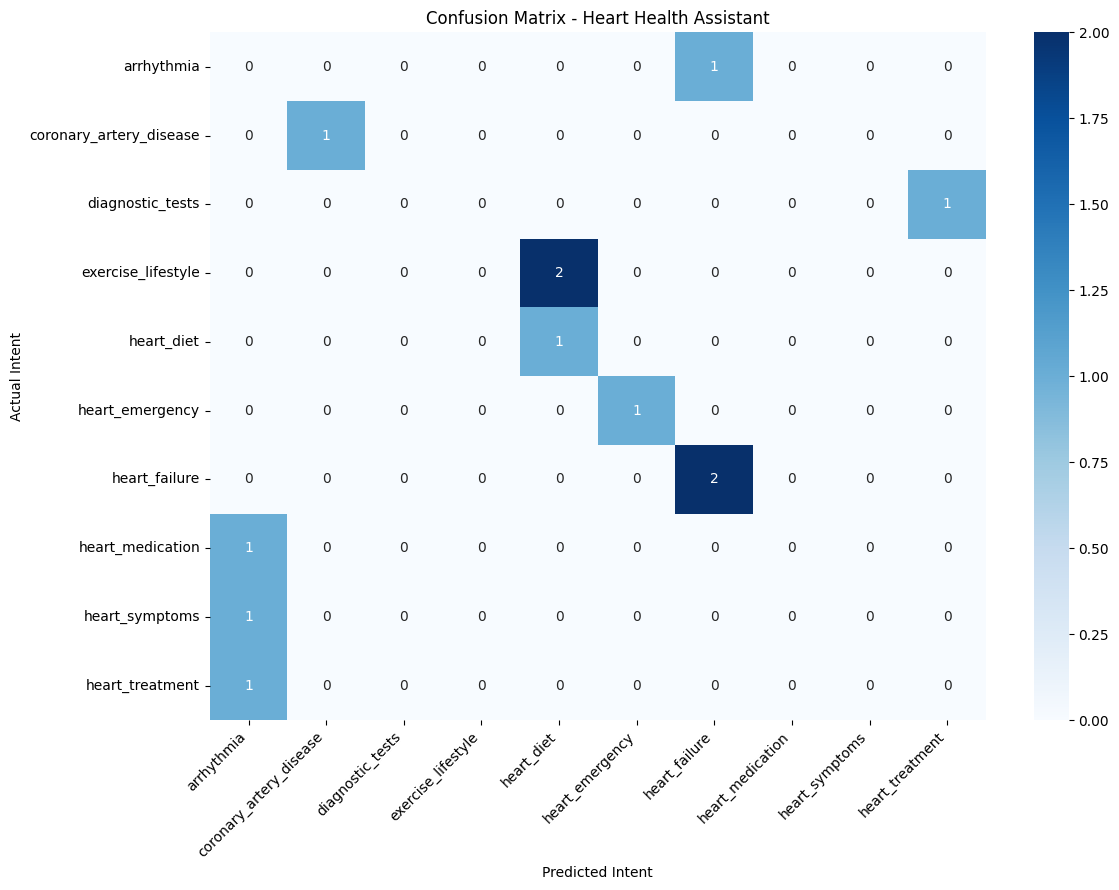

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix - Heart Health Assistant")

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
knowledge_base = {

    "coronary_artery_disease": {
        "title": "Coronary Artery Disease",

        "information": """
        Coronary artery disease (CAD) occurs when the arteries
        supplying blood to the heart become narrowed or blocked.

        It commonly develops due to the accumulation of plaque
        inside artery walls.

        Risk factors include high cholesterol, smoking, diabetes,
        high blood pressure, physical inactivity and family history.

        Prevention includes a balanced diet, regular physical
        activity, avoiding tobacco and managing blood pressure
        and cholesterol.
        """
    },

    "arrhythmia": {
        "title": "Cardiac Arrhythmia",

        "information": """
        Arrhythmia refers to an abnormal heartbeat.

        The heart may beat too fast, too slowly or irregularly.

        Some arrhythmias are harmless, while others may require
        medical attention.

        Diagnosis may involve an ECG or heart rhythm monitoring.
        """
    },

    "heart_symptoms": {
        "title": "Heart-Related Symptoms",

        "information": """
        Common symptoms associated with heart conditions include
        chest discomfort, breathlessness, unusual fatigue,
        dizziness and palpitations.

        Symptoms vary between individuals.

        Severe or sudden symptoms require immediate medical
        evaluation.
        """
    },

    "diagnostic_tests": {
        "title": "Cardiac Diagnostic Tests",

        "information": """
        Common heart diagnostic tests include:

        1. ECG: Records electrical activity of the heart.
        2. Echocardiogram: Uses ultrasound to examine heart
           structure and pumping function.
        3. Stress Test: Evaluates the heart during physical
           activity or medically induced stress.
        4. Cardiac MRI: Provides detailed images of the heart.

        The appropriate test depends on the patient's condition
        and the doctor's assessment.
        """
    },

    "heart_diet": {
        "title": "Heart-Healthy Diet",

        "information": """
        A heart-healthy diet emphasizes fruits, vegetables,
        whole grains, legumes, nuts and appropriate protein sources.

        Limiting excessive salt, saturated fat, trans fat and
        highly processed foods can support cardiovascular health.

        Dietary requirements may vary depending on individual
        medical conditions.
        """
    },

    "exercise_lifestyle": {
        "title": "Exercise and Lifestyle",

        "information": """
        Regular physical activity supports cardiovascular health.

        Walking, cycling and swimming are examples of aerobic
        activities.

        Avoiding smoking, getting adequate sleep and managing
        stress are also important.

        People with existing heart conditions should discuss
        suitable exercise levels with their healthcare provider.
        """
    },

    "heart_medication": {
        "title": "Heart Medications",

        "information": """
        Different medications are used to manage cardiovascular
        conditions.

        Examples include:

        1. Statins: Help lower cholesterol.
        2. Beta blockers: Reduce heart rate and workload in
           certain conditions.
        3. Antiplatelet medicines: Help prevent blood clots
           in appropriate patients.
        4. Antihypertensive medicines: Help control blood pressure.

        Medication selection and dosage must be determined
        by a qualified healthcare professional.
        """
    },

    "heart_treatment": {
        "title": "Heart Treatments",

        "information": """
        Treatment depends on the specific heart condition.

        Common procedures include:

        1. Angioplasty: Opens narrowed coronary arteries.
        2. Stent placement: Helps keep an artery open.
        3. Coronary bypass surgery: Creates an alternative
           route for blood flow.
        4. Pacemaker implantation: Helps regulate certain
           abnormal heart rhythms.

        Treatment decisions require medical evaluation.
        """
    },

    "heart_failure": {
        "title": "Heart Failure",

        "information": """
        Heart failure is a condition in which the heart cannot
        pump blood adequately to meet the body's needs.

        Symptoms may include breathlessness, fatigue and swelling
        in the legs or ankles.

        Management may involve medication, lifestyle changes
        and medical procedures depending on the condition.
        """
    },

    "heart_emergency": {
        "title": "Cardiac Emergencies",

        "information": """
        A heart attack may cause chest pressure or discomfort,
        pain in the arm, back, neck or jaw, breathlessness,
        sweating, nausea or lightheadedness.

        Symptoms can vary, and some people may experience
        less typical symptoms.

        If a heart attack is suspected, seek emergency medical
        assistance immediately. Do not wait for symptoms to
        disappear.
        """
    }
}

In [ ]:
def retrieve_information(intent):

    if intent in knowledge_base:

        title = knowledge_base[intent]["title"]

        information = knowledge_base[intent]["information"]

        return title + "\n" + information

    else:
        return "Information is not available in the knowledge base."

In [ ]:
emergency_keywords = [

    "heart attack",
    "cardiac arrest",
    "severe chest pain",
    "crushing chest pain",
    "chest pressure",
    "cannot breathe",
    "difficulty breathing",
    "shortness of breath",
    "unconscious",
    "collapsed",
    "not breathing"
]

In [ ]:
unsupported_topics = [

    "kidney",
    "diabetes",
    "migraine",
    "cancer",
    "pregnancy",
    "skin infection",
    "stomach infection",
    "dental",
    "arthritis"
]

In [ ]:
def reasoning_engine(query, predicted_intent, confidence):

    query_lower = query.lower()

    for keyword in emergency_keywords:

        if keyword in query_lower:

            return """
            EMERGENCY ALERT!

            Your query contains symptoms or circumstances
            that may indicate a medical emergency.

            Call India's emergency number 112 immediately
            or contact emergency medical services.

            Do not wait for an AI response or attempt
            to self-diagnose.

            Follow the instructions of emergency professionals.
            """


    for topic in unsupported_topics:

        if topic in query_lower:

            return """
            UNSUPPORTED QUERY

            I am a Heart Health Information Assistant.

            I currently provide information about heart
            conditions, symptoms, diagnosis, prevention,
            medication and cardiac emergencies.

            Your query appears to concern a different
            healthcare domain.

            Please consult an appropriate healthcare professional.
            """


    if confidence < 0.35:

        return """
        LOW CONFIDENCE

        I could not confidently understand your query.

        Please rephrase your question using simpler words.

        You can ask me about heart conditions, symptoms,
        diagnostic tests, diet, exercise or treatment.
        """


    if predicted_intent in knowledge_base:

        response = retrieve_information(predicted_intent)


        if predicted_intent == "heart_medication":

            response += """

            IMPORTANT:
            This information is educational only.
            Do not start, stop or change any medication
            without consulting your doctor.
            """

        return response


    return """
    I am unable to process this query.

    Please ask a question related to heart health.
    """

In [ ]:
def heart_health_assistant(query):

    if not query.strip():
        return "Please enter a healthcare question."
    processed_query = preprocess_text(query)
    query_vector = tfidf.transform([processed_query])
    predicted_intent = model.predict(query_vector)[0]
    probabilities = model.predict_proba(query_vector)[0]
    confidence = np.max(probabilities)
    response = reasoning_engine(
        query,
        predicted_intent,
        confidence
    )
    result = f"""
    PREDICTED INTENT: {predicted_intent}
    CONFIDENCE: {confidence:.2%}
    PROCESSED QUERY: {processed_query}
    ASSISTANT RESPONSE:
    {response}
    Disclaimer: This assistant provides general educational
    information and does not replace professional medical advice.
    """
    return result

In [ ]:
def chatbot_interface(user_input):

    if not user_input.strip():
        return "Please enter a question."

    queries = user_input.split('\n')

    responses = []

    for i, query in enumerate(queries):

        if query.strip():

            response = heart_health_assistant(query)

            responses.append(
                f"QUERY {i+1}:\n{query}\n\n{response}"
            )

    return "\n\n================================\n\n".join(responses)

In [ ]:
demo = gr.Interface(

    fn=chatbot_interface,

    inputs=gr.Textbox(
        lines=5,
        placeholder="Ask me anything about heart health...",
        label="Enter Your Healthcare Query"
    ),

    outputs=gr.Textbox(
        lines=20,
        label="Heart Health Assistant Response"
    ),

    title="Heart Health Information Assistant",

    description="""
    An AI-powered healthcare cognitive assistant
    using NLP, TF-IDF, Naive Bayes classification,
    rule-based reasoning and knowledge retrieval.
    """
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0a9804250f7cc67530.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
